In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


In [2]:
!pip install catboost

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import root_mean_squared_log_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor,GradientBoostingRegressor, HistGradientBoostingRegressor


from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
pd.options.display.float_format = '{:.4f}'.format

In [6]:
train = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv")
train.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0000,117665,88,ACH138,GTX,1997,4640.0000,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0000,1001282,4616,ACH138,GTX,2005,508.0000,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0000,772709,1948,ACH138,GTX,1994,11540.0000,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0000,902010,3550,ACH138,GTX,2002,4883.0000,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0000,1036259,36014,ACH138,GTX,2009,302.0000,Low,2010-08-27,...,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


In [7]:
test = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")
test.head()

,TransactionID,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139307,999097,3168,ACH138,GTX,2005,68.0000,Low,2007-11-16,521D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139419,1018084,1344,ACH138,GTX,1999,10466.0000,Medium,2007-06-01,345BL,...,Steel,None or Unspecified,"15' 9""",None or Unspecified,Yes,Double,NaN,NaN,NaN,NaN
2,1139482,1048712,2808,ACH138,GTX,2001,3817.0000,Low,2012-06-16,EX120-5,...,Steel,None or Unspecified,None or Unspecified,Hydraulic,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139522,697537,1089,ACH138,GTX,2006,1498.0000,Medium,2010-08-27,304CR,...,Rubber,16 inch,None or Unspecified,Manual,Yes,Double,NaN,NaN,NaN,NaN
4,1139684,1048082,16781,ACH138,GTX,2009,22.0000,Low,2010-07-09,L2800D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Exploratory Data Analysis (EDA)

*   Dataset shape
*   Missing values
*   Duplicate records
*   Data types
*   Summary statistics
*   Target distribution
*   Correlation analysis
*   Outlier detection
*   Category frequencies
*   High-cardinality feature analysis
  

### Train Shape

In [8]:
print(train.shape)

(138701, 50)


### Test Shape

In [9]:
print(test.shape)

(15000, 49)


### Training Data Info

In [10]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

### Descriptive Statistics of Train Data

In [11]:
train.describe(include="all")

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
count,138701.0000,138701.0000,138701.0000,138701.0000,138701,138701,138701.0000,82058.0000,50475,138701,...,71016,71016,71018,71018,71018,71016,14959,14959,18872,18872
unique,NaN,NaN,NaN,NaN,6,31,NaN,NaN,3,3676,...,2,18,27,3,3,3,9,5,3,2
top,NaN,NaN,NaN,NaN,ADI149,UJF,NaN,NaN,Medium,2010-02-16,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,PAT,None or Unspecified,Standard,Conventional
freq,NaN,NaN,NaN,NaN,59541,67828,NaN,NaN,24588,1159,...,62023,56910,54059,57368,63132,60406,7091,10537,18220,18464
mean,2186275.9506,41521.8740,1204814.3204,7286.4219,NaN,NaN,1891.6409,4553.7189,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1128496.6193,26361.1259,528737.5934,7542.4215,NaN,NaN,306.9920,27922.0448,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1139309.0000,7500.0000,8.0000,39.0000,NaN,NaN,1001.0000,0.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1465754.0000,20500.0000,1007930.0000,1693.0000,NaN,NaN,1990.0000,0.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1751884.0000,35000.0000,1246956.0000,3852.0000,NaN,NaN,1998.0000,1620.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2372139.0000,57000.0000,1495817.0000,11873.0000,NaN,NaN,2004.0000,5001.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing Values

In [12]:
missing = train.isnull().sum()

missing = missing[missing > 0]

missing = missing.sort_values(ascending=False)

missing

col18                    138635
col19                    138635
col4                     128320
col5                     128320
col28                    123742
col27                    123742
col30                    119829
col29                    119829
col14                    115296
col11                    115296
col13                    115296
col8                     115296
col9                     115296
col6                     115296
col7                     115296
col3                     109448
Forks                    109382
Spec_ReleaseSeries       105805
col1                     104915
col12                    100337
col15                     96424
DrivetrainType            89956
UtilizationTier           88226
Spec_VariantModifier      86369
col21                     67685
col20                     67685
col25                     67685
col23                     67683
col24                     67683
col22                     67683
OperationalHoursMeter     56643
col16   

### Percentage of missing values

In [13]:
missing_percent = train.isnull().mean()*100

missing_percent.sort_values(ascending=False)

col19                       99.9524
col18                       99.9524
col5                        92.5156
col4                        92.5156
col27                       89.2149
col28                       89.2149
col29                       86.3938
col30                       86.3938
col13                       83.1256
col14                       83.1256
col7                        83.1256
col6                        83.1256
col9                        83.1256
col8                        83.1256
col11                       83.1256
col3                        78.9093
Forks                       78.8617
Spec_ReleaseSeries          76.2828
col1                        75.6411
col12                       72.3405
col15                       69.5193
DrivetrainType              64.8561
UtilizationTier             63.6088
Spec_VariantModifier        62.2699
col20                       48.7992
col25                       48.7992
col21                       48.7992
col22                       

### Target Distribution

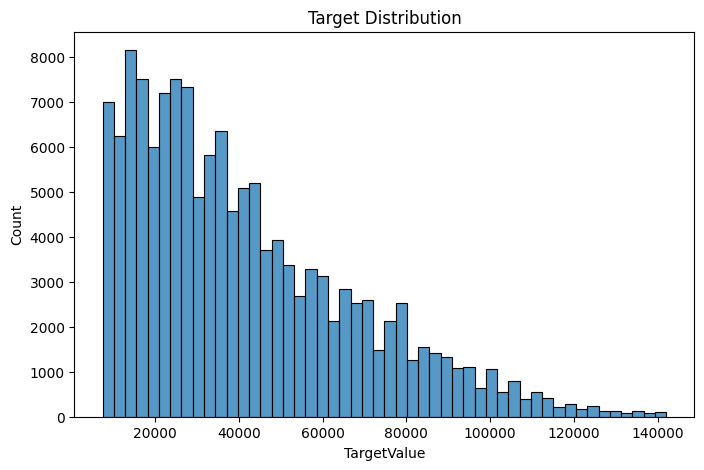

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(train["TargetValue"], bins=50)

plt.title("Target Distribution")

plt.show()

#### Log Scale

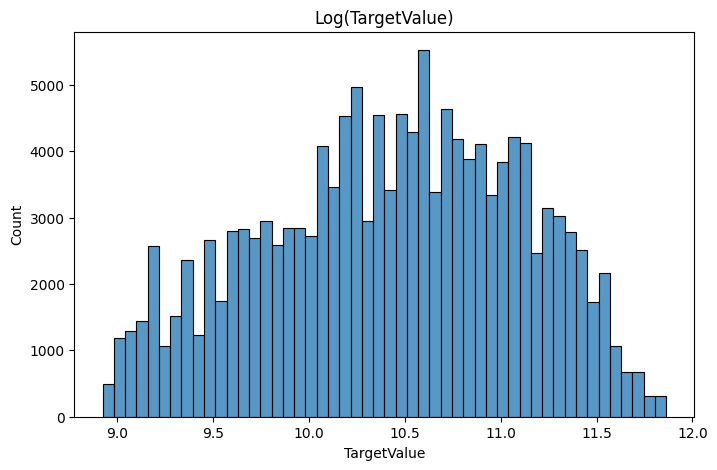

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(np.log1p(train["TargetValue"]), bins=50)

plt.title("Log(TargetValue)")

plt.show()

### Correlation Analysis

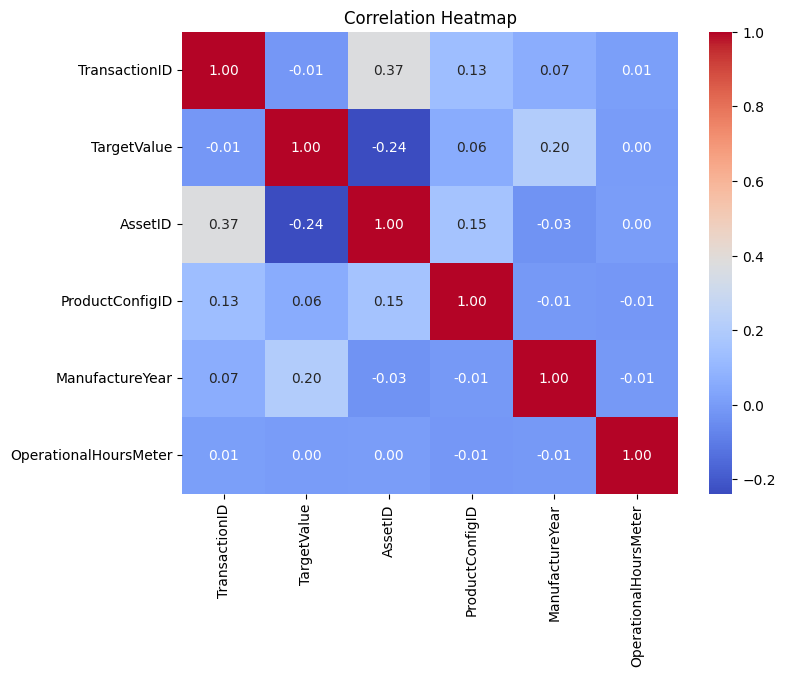

In [16]:
num_cols = train.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(8,6))
sns.heatmap(num_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### Outlier Detection

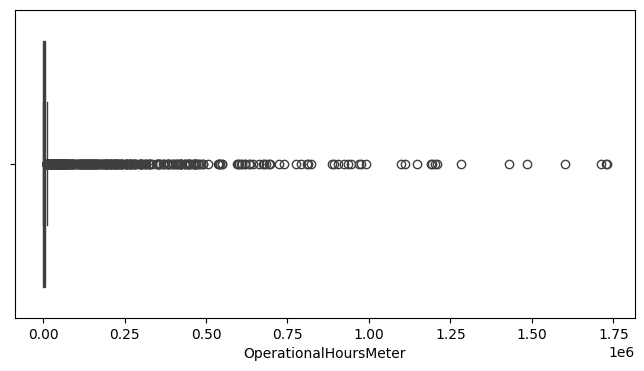

In [17]:
plt.figure(figsize=(8,4))
sns.boxplot(x=train["OperationalHoursMeter"])
plt.show()

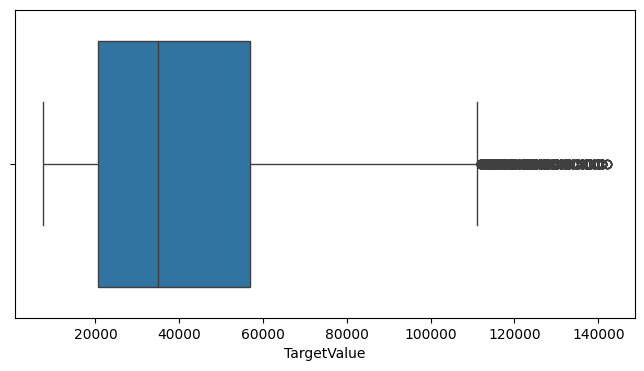

In [18]:
plt.figure(figsize=(8,4))
sns.boxplot(x=train["TargetValue"])
plt.show()

### Category Frequencies

In [19]:
cat_cols = [
    "RegionCode",
    "CabinType",
    "UtilizationTier",
    "Spec_BaseClass",
    "FunctionalClassification"
]

for col in cat_cols:
    print(f"\n{col}")
    print(train[col].value_counts(dropna=False).head(10))


RegionCode
RegionCode
Florida           23460
Texas             18284
California         9525
Washington         6063
Georgia            5240
North Carolina     4391
Maryland           4352
Mississippi        4227
Colorado           3989
Illinois           3855
Name: count, dtype: int64

CabinType
CabinType
EROPS         60189
EROPS w AC    55752
OROPS         22760
Name: count, dtype: int64

UtilizationTier
UtilizationTier
NaN       88226
Medium    24588
Low       17005
High       8882
Name: count, dtype: int64

Spec_BaseClass
Spec_BaseClass
12       5702
140      5378
320      4605
D6       4347
330      3870
D5       3076
950      2585
PC200    2531
580      2474
120      2424
Name: count, dtype: int64

FunctionalClassification
FunctionalClassification
Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons      11158
Motorgrader - 145.0 to 170.0 Horsepower                     8107
Hydraulic Excavator, Track - 12.0 to 14.0 Metric Tons       7625
Backhoe Loader - 14.0 to 15.0 Ft Stand

### High Cardinality Analysis

In [20]:
cat_columns = train.select_dtypes(include="object").columns

cardinality = (
    train[cat_columns]
    .nunique()
    .sort_values(ascending=False)
)

cardinality

TransactionDate              3676
Spec_FullDescriptor          3505
Spec_BaseClass               1249
Spec_SubClass                 147
Spec_VariantModifier          132
Spec_ReleaseSeries            113
FunctionalClassification       65
RegionCode                     53
VendorPartnerID                31
col22                          27
col21                          18
col15                          15
col10                          11
col27                           9
DrivetrainType                  8
DataOriginCode                  6
col7                            6
AssetScaleFactor                6
InventoryGroupDescription       6
InventoryGroupCategory          6
col28                           5
col1                            4
col12                           4
UtilizationTier                 3
col3                            3
col8                            3
col23                           3
CabinType                       3
col25                           3
col24         

#### Visual plotting of cardinality

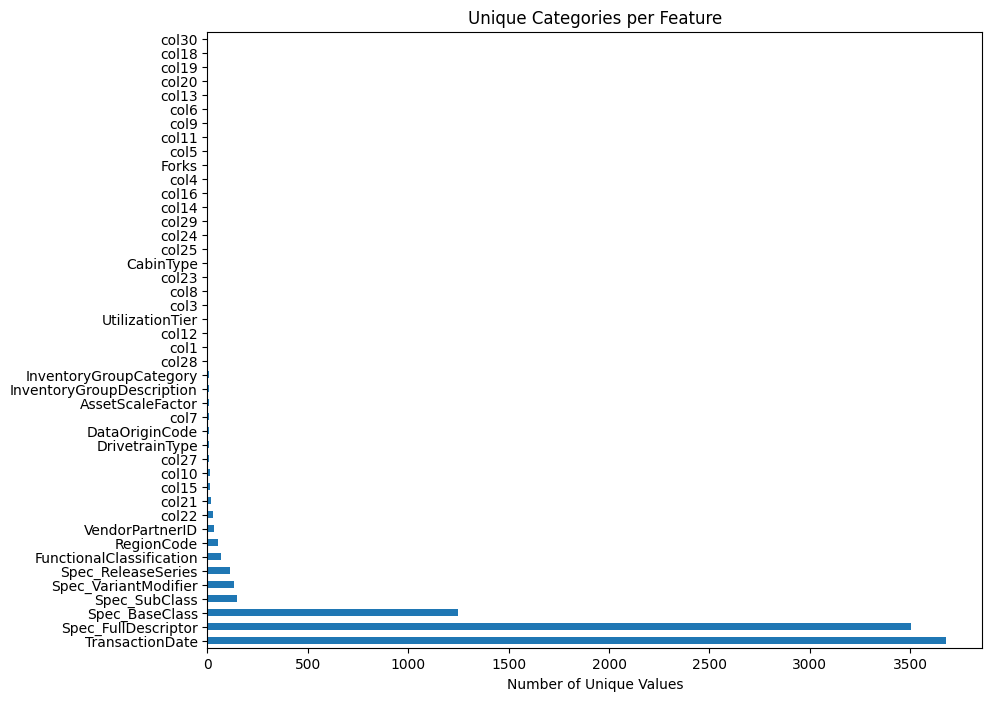

In [21]:
plt.figure(figsize=(10,8))
cardinality.plot(kind="barh")
plt.title("Unique Categories per Feature")
plt.xlabel("Number of Unique Values")
plt.show()

### Description of Manufacturing Year

In [22]:
print(train["ManufactureYear"].describe())
print(train["ManufactureYear"].value_counts().head(20))
print(train["ManufactureYear"].value_counts().tail(20))

count   138701.0000
mean      1891.6409
std        306.9920
min       1001.0000
25%       1990.0000
50%       1998.0000
75%       2004.0000
max       2015.0000
Name: ManufactureYear, dtype: float64
ManufactureYear
1001    14719
2006    10895
2005     9564
1999     7243
2007     7133
1998     6447
1997     6151
2000     6096
2004     6019
2001     5764
1996     5673
1995     5222
2002     5136
2003     4659
1994     4000
1991     3134
1990     2808
2008     2657
1993     2613
1992     2443
Name: count, dtype: int64
ManufactureYear
1963    60
1961    54
1962    41
2011    32
1959    13
1920    13
1957     8
1921     7
2012     6
1958     4
1952     3
1953     3
1951     2
1960     2
1954     2
1949     1
1955     1
2013     1
2014     1
2015     1
Name: count, dtype: int64


In [23]:
corr = train.select_dtypes(include=["int64","float64"]).corr()["TargetValue"].sort_values(ascending=False)
print(corr)

TargetValue              1.0000
ManufactureYear          0.2044
ProductConfigID          0.0573
OperationalHoursMeter    0.0020
TransactionID           -0.0121
AssetID                 -0.2387
Name: TargetValue, dtype: float64


In [24]:
print(train["TransactionDate"].head())

print(test["TransactionDate"].head())

0    2005-03-26
1    2009-12-18
2    2005-08-26
3    2006-11-17
4    2010-08-27
Name: TransactionDate, dtype: object
0    2007-11-16
1    2007-06-01
2    2012-06-16
3    2010-08-27
4    2010-07-09
Name: TransactionDate, dtype: object


## Cleaning and Modification of Data

Copies for Train Data

In [25]:
train_copy = train.copy()
test_copy = test.copy()

In [26]:
train_copy.shape, test_copy.shape,train_copy.columns

((138701, 50),
 (15000, 49),
 Index(['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID',
        'DataOriginCode', 'VendorPartnerID', 'ManufactureYear',
        'OperationalHoursMeter', 'UtilizationTier', 'TransactionDate',
        'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass',
        'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor',
        'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory',
        'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3',
        'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9',
        'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18',
        'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27',
        'col28', 'col29', 'col30'],
       dtype='object'))

In [27]:
drop_cols = ["col18", "col19", "col4", "col5"]

train_copy.drop(columns=drop_cols, inplace=True)
test_copy.drop(columns=drop_cols, inplace=True)

In [28]:
train_copy.shape, test_copy.shape

((138701, 46), (15000, 45))

### Fixing Invalid Values

In [29]:
train_copy["ManufactureYear"] = train_copy["ManufactureYear"].replace(1001, np.nan)
test_copy["ManufactureYear"] = test_copy["ManufactureYear"].replace(1001, np.nan)

In [30]:
train_copy["ManufactureYear"].value_counts().head()

ManufactureYear
2006.0000    10895
2005.0000     9564
1999.0000     7243
2007.0000     7133
1998.0000     6447
Name: count, dtype: int64

In [31]:
# Train: DD-MM-YYYY
train_copy["TransactionDate"] = pd.to_datetime(
    train_copy["TransactionDate"],
    format="%Y-%m-%d"
)

# Test: YYYY-MM-DD
test_copy["TransactionDate"] = pd.to_datetime(
    test_copy["TransactionDate"],
    format="%Y-%m-%d"
)

In [32]:
train_copy["TransactionDate"].dtype

dtype('<M8[ns]')

In [33]:
for df in [train_copy, test_copy]:

    df["TransactionYear"] = df["TransactionDate"].dt.year
    df["TransactionMonth"] = df["TransactionDate"].dt.month
    df["TransactionQuarter"] = df["TransactionDate"].dt.quarter
    df["TransactionWeekday"] = df["TransactionDate"].dt.dayofweek

In [34]:
for df in [train_copy, test_copy]:

    df["AssetAge"] = (
        df["TransactionYear"] - df["ManufactureYear"]
    )

    # Avoid negative ages caused by invalid data
    df.loc[df["AssetAge"] < 0, "AssetAge"] = np.nan

In [35]:
for df in [train_copy, test_copy]:

    df["DescriptorLength"] = (
        df["Spec_FullDescriptor"]
        .astype(str)
        .str.len()
    )

In [36]:
for df in [train_copy, test_copy]:

    df["HasOperationalHours"] = (
        df["OperationalHoursMeter"]
        .notna()
        .astype(int)
    )

    df["HasVariantModifier"] = (
        df["Spec_VariantModifier"]
        .notna()
        .astype(int)
    )

    df["HasReleaseSeries"] = (
        df["Spec_ReleaseSeries"]
        .notna()
        .astype(int)
    )

    df["HasSubclass"] = (
        df["Spec_SubClass"]
        .notna()
        .astype(int)
    )

In [37]:
for df in [train_copy, test_copy]:

    df["HoursPerYear"] = (
        df["OperationalHoursMeter"] /
        df["AssetAge"]
    )

    df["HoursPerYear"].replace([np.inf, -np.inf], np.nan, inplace=True)

In [38]:
train_copy.drop(columns=['TransactionDate'], inplace=True)
test_copy.drop(columns=["TransactionDate"], inplace=True)

In [39]:
train_copy.shape,train_copy.head()

((138701, 56),
    TransactionID  TargetValue  AssetID  ProductConfigID DataOriginCode  \
 0        1139309   57000.0000   117665               88         ACH138   
 1        1139316   26500.0000  1001282             4616         ACH138   
 2        1139317   21000.0000   772709             1948         ACH138   
 3        1139322   27000.0000   902010             3550         ACH138   
 4        1139333   21500.0000  1036259            36014         ACH138   
 
   VendorPartnerID  ManufactureYear  OperationalHoursMeter UtilizationTier  \
 0             GTX        1997.0000              4640.0000             Low   
 1             GTX        2005.0000               508.0000             Low   
 2             GTX        1994.0000             11540.0000            High   
 3             GTX        2002.0000              4883.0000            High   
 4             GTX        2009.0000               302.0000             Low   
 
   Spec_FullDescriptor  ... TransactionMonth TransactionQuarter

In [40]:
X = train_copy.drop(columns="TargetValue")
y = train_copy["TargetValue"]

X_test = test_copy.copy()

In [41]:
X.shape, y.shape, X_test.shape

((138701, 55), (138701,), (15000, 55))

##### Numerical + Categorical Columns

In [42]:
numeric_cols = X.select_dtypes(include=["int32","int64", "float64"]).columns.tolist()

categorical_cols = X.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))

Numerical Columns: 16
Categorical Columns: 39


## High Cardinality Columns

In [43]:
cardinality = X[categorical_cols].nunique().sort_values(ascending=False)

print(cardinality)

Spec_FullDescriptor          3505
Spec_BaseClass               1249
Spec_SubClass                 147
Spec_VariantModifier          132
Spec_ReleaseSeries            113
FunctionalClassification       65
RegionCode                     53
VendorPartnerID                31
col22                          27
col21                          18
col15                          15
col10                          11
col27                           9
DrivetrainType                  8
DataOriginCode                  6
col7                            6
InventoryGroupDescription       6
InventoryGroupCategory          6
AssetScaleFactor                6
col28                           5
col12                           4
col1                            4
UtilizationTier                 3
col25                           3
col24                           3
col29                           3
col8                            3
col3                            3
CabinType                       3
col16         

In [44]:
high_cardinality = cardinality[cardinality > 50].index.tolist()
low_cardinality = cardinality[cardinality <= 50].index.tolist()

print("High Cardinality Columns:")
print(high_cardinality)

print("\nLow Cardinality Columns:")
print(low_cardinality)

High Cardinality Columns:
['Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_VariantModifier', 'Spec_ReleaseSeries', 'FunctionalClassification', 'RegionCode']

Low Cardinality Columns:
['VendorPartnerID', 'col22', 'col21', 'col15', 'col10', 'col27', 'DrivetrainType', 'DataOriginCode', 'col7', 'InventoryGroupDescription', 'InventoryGroupCategory', 'AssetScaleFactor', 'col28', 'col12', 'col1', 'UtilizationTier', 'col25', 'col24', 'col29', 'col8', 'col3', 'CabinType', 'col16', 'col14', 'col23', 'col9', 'Forks', 'col6', 'col20', 'col13', 'col11', 'col30']


# Train-Test Split

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [46]:
print(X_train.shape)
print(X_valid.shape)

(110960, 55)
(27741, 55)


## Frequency Encoding

In [47]:
high_cardinality = [
    "Spec_FullDescriptor",
    "Spec_BaseClass",
    "Spec_SubClass",
    "Spec_VariantModifier",
    "Spec_ReleaseSeries",
    "FunctionalClassification",
    "RegionCode"
]

for col in high_cardinality:

    freq = X_train[col].value_counts(normalize=True)

    X_train[col] = X_train[col].map(freq)

    X_valid[col] = X_valid[col].map(freq)

    X_test[col] = X_test[col].map(freq)

In [48]:
for col in high_cardinality:
    X_valid[col] = X_valid[col].fillna(0)
    X_test[col] = X_test[col].fillna(0)

In [49]:
low_cardinality = X_train.select_dtypes(include="object").columns.tolist()

print(low_cardinality)

['DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'AssetScaleFactor', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'DrivetrainType', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']


In [50]:
# Numerical columns
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

# Remaining categorical columns
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()

print("Numeric:", len(numeric_cols))
print("Categorical:", len(categorical_cols))

Numeric: 23
Categorical: 32


## Numeric Pipeline

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

## Categorical Pipeline

In [52]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [53]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [54]:
X_train_proc = preprocessor.fit_transform(X_train)

X_valid_proc = preprocessor.transform(X_valid)

X_test_proc = preprocessor.transform(X_test)

In [55]:
print(X_train_proc.shape)
print(X_valid_proc.shape)
print(X_test_proc.shape)

(110960, 227)
(27741, 227)
(15000, 227)


In [56]:
print(np.isnan(X_train_proc).sum())
print(np.isnan(X_valid_proc).sum())
print(np.isnan(X_test_proc).sum())

0
0
0


## Model Training

### Linear Regression

In [57]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_proc, y_train)

pred = lr.predict(X_valid_proc)

pred = np.clip(pred, 0, None)

In [58]:
from sklearn.metrics import root_mean_squared_log_error

rmsle = root_mean_squared_log_error(y_valid, pred)

print("Linear Regression RMSLE:", rmsle)

Linear Regression RMSLE: 1.4680351459548775


In [59]:
# Range of values for Linear Regression

print(pred.min())
print(pred.max())
print(pred[:10])

0.0
123948.05400684143
[72611.14333733 53135.39199449 66469.22967905  5150.95088945
 34208.48640535 38690.02619088 54521.93106972 45018.49675482
 67153.68906688 39396.33771199]


### Extra Trees

In [60]:
from sklearn.ensemble import ExtraTreesRegressor

et = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

et.fit(X_train_proc, y_train)

pred_et = et.predict(X_valid_proc)

pred_et = np.clip(pred_et, 0, None)

rmsle_et = root_mean_squared_log_error(y_valid, pred_et)

print("Extra Trees RMSLE:", rmsle_et)

Extra Trees RMSLE: 0.25401377425854155


### Random Forest Regressor

In [61]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_proc, y_train)

pred = rf.predict(X_valid_proc)
pred = np.clip(pred, 0, None)

print(root_mean_squared_log_error(y_valid, pred))

0.2989280951702533


### HistGradientBoosting


In [62]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(
    random_state=42
)

hgb.fit(X_train_proc, y_train)

pred = hgb.predict(X_valid_proc)
pred = np.clip(pred, 0, None)

print(root_mean_squared_log_error(y_valid, pred))

0.29081242122735773


#### XGBoost

In [63]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train_proc, y_train)

pred = np.clip(xgb.predict(X_valid_proc), 0, None)

print(root_mean_squared_log_error(y_valid, pred))

0.31766593778118407


#### LightGBM

In [64]:
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42
)

lgbm.fit(X_train_proc, y_train)

pred = np.clip(lgbm.predict(X_valid_proc), 0, None)

print(root_mean_squared_log_error(y_valid, pred))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.055101 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2629
[LightGBM] [Info] Number of data points in the train set: 110960, number of used features: 212
[LightGBM] [Info] Start training from score 41559.253875
0.27030809868269123


### CatBoost

In [65]:
drop_ids = ["TransactionID", "AssetID", "ProductConfigID"]

X_cb = train_copy.drop(columns=["TargetValue"] + drop_ids)
y_cb = train_copy["TargetValue"]

X_test_cb = test_copy.drop(columns=drop_ids)

In [66]:
from sklearn.model_selection import train_test_split

X_train_cb, X_valid_cb, y_train_cb, y_valid_cb = train_test_split(
    X_cb,
    y_cb,
    test_size=0.2,
    random_state=42
)

In [67]:
cat_features = X_train_cb.select_dtypes(include="object").columns.tolist()

print("Number of categorical columns:", len(cat_features))
print(cat_features)

Number of categorical columns: 39
['DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'DrivetrainType', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']


In [68]:
for col in cat_features:
    X_train_cb[col] = X_train_cb[col].fillna("Missing")
    X_valid_cb[col] = X_valid_cb[col].fillna("Missing")
    X_test_cb[col] = X_test_cb[col].fillna("Missing")

In [69]:
cb = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.03,
    depth=6,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    early_stopping_rounds=200,
    verbose=200
)

In [70]:
cb.fit(
    X_train_cb,
    y_train_cb,
    cat_features=cat_features,
    eval_set=(X_valid_cb, y_valid_cb),
    use_best_model=True
)

0:	learn: 25934.0283504	test: 25709.4608661	best: 25709.4608661 (0)	total: 441ms	remaining: 14m 42s
200:	learn: 11224.4266098	test: 10815.7658754	best: 10815.7658754 (200)	total: 1m 5s	remaining: 9m 43s
400:	learn: 10294.4299174	test: 9937.7020531	best: 9937.7020531 (400)	total: 2m 16s	remaining: 9m 2s
600:	learn: 9816.6495926	test: 9512.6832828	best: 9512.6832828 (600)	total: 3m 29s	remaining: 8m 6s
800:	learn: 9529.1398052	test: 9266.5985748	best: 9266.5985748 (800)	total: 4m 41s	remaining: 7m 1s
1000:	learn: 9330.0296876	test: 9100.8734371	best: 9100.8734371 (1000)	total: 5m 53s	remaining: 5m 52s
1200:	learn: 9182.2218827	test: 8986.8877730	best: 8986.8877730 (1200)	total: 7m 5s	remaining: 4m 43s
1400:	learn: 9059.5541339	test: 8892.9044928	best: 8892.9044928 (1400)	total: 8m 19s	remaining: 3m 33s
1600:	learn: 8956.5394911	test: 8818.0356287	best: 8818.0356287 (1600)	total: 9m 32s	remaining: 2m 22s
1800:	learn: 8870.5478832	test: 8758.2574888	best: 8758.2574888 (1800)	total: 10m 45s

CatBoostRegressor(depth=6, early_stopping_rounds=200, eval_metric='RMSE', iterations=2000, learning_rate=0.03, loss_function='RMSE', random_seed=42, verbose=200)

In [71]:
pred_cb = cb.predict(X_valid_cb)

pred_cb = np.clip(pred_cb, 0, None)

In [72]:
from sklearn.metrics import root_mean_squared_log_error

rmsle_cb = root_mean_squared_log_error(
    y_valid_cb,
    pred_cb
)

print("CatBoost RMSLE:", rmsle_cb)

CatBoost RMSLE: 0.2312909982786282


In [73]:
importance = pd.DataFrame({
    "Feature": X_train_cb.columns,
    "Importance": cb.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(20))

                     Feature  Importance
5        Spec_FullDescriptor     18.7871
45                  AssetAge     17.5635
11  FunctionalClassification     13.7805
2            ManufactureYear     11.5442
41           TransactionYear     11.1195
7              Spec_SubClass      5.7950
16                 CabinType      2.9545
6             Spec_BaseClass      2.8944
10          AssetScaleFactor      2.0117
20                      col6      1.5237
42          TransactionMonth      1.1450
26                     col12      1.0797
9       Spec_VariantModifier      1.0557
27                     col13      0.9088
29                     col15      0.6774
22                      col8      0.6079
15                      col1      0.5667
25                     col11      0.5044
46          DescriptorLength      0.4845
4            UtilizationTier      0.4656


# Final Submission

In [74]:
drop_cols = ["TransactionID", "AssetID", "ProductConfigID"]

X_final = train_copy.drop(columns=["TargetValue"] + drop_cols)
y_final = train_copy["TargetValue"]

X_test_final = test_copy.drop(columns=drop_cols)

In [75]:
cat_features = X_final.select_dtypes(include="object").columns.tolist()

In [76]:
for col in cat_features:
    X_final[col] = X_final[col].fillna("Missing")
    X_test_final[col] = X_test_final[col].fillna("Missing")

In [77]:
from catboost import CatBoostRegressor

final_model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.03,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    task_type="GPU",
    devices="0",
    verbose=200
)

final_model.fit(
    X_final,
    y_final,
    cat_features=cat_features
)

0:	learn: 25851.4377201	total: 5.14s	remaining: 4h 16m 45s
200:	learn: 11076.6886283	total: 17.1s	remaining: 3m 58s
400:	learn: 10157.9154911	total: 28.5s	remaining: 3m 4s
600:	learn: 9718.3983178	total: 39.9s	remaining: 2m 39s
800:	learn: 9450.6311350	total: 51.3s	remaining: 2m 20s
1000:	learn: 9267.5268549	total: 1m 2s	remaining: 2m 4s
1200:	learn: 9134.4163384	total: 1m 13s	remaining: 1m 50s
1400:	learn: 9028.1265763	total: 1m 24s	remaining: 1m 36s
1600:	learn: 8937.0796925	total: 1m 35s	remaining: 1m 23s
1800:	learn: 8857.6172524	total: 1m 46s	remaining: 1m 10s
2000:	learn: 8788.3004559	total: 1m 57s	remaining: 58.6s
2200:	learn: 8717.9699428	total: 2m 8s	remaining: 46.5s
2400:	learn: 8660.3305944	total: 2m 19s	remaining: 34.7s
2600:	learn: 8604.5088713	total: 2m 30s	remaining: 23s
2800:	learn: 8551.4023768	total: 2m 41s	remaining: 11.4s
2999:	learn: 8504.4304342	total: 2m 52s	remaining: 0us


CatBoostRegressor(depth=6, devices='0', iterations=3000, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='GPU', verbose=200)

In [78]:
test_predictions = final_model.predict(X_test_final)

test_predictions = np.clip(test_predictions, 0, None)

In [79]:
submission = pd.DataFrame({
    "TransactionID": test["TransactionID"],
    "TargetValue": test_predictions
})

submission.head()

,TransactionID,TargetValue
0,1139307,65635.6518
1,1139419,83002.7154
2,1139482,29175.3952
3,1139522,19263.2449
4,1139684,18821.7188


In [80]:
submission.to_csv("submission.csv", index=False)

In [81]:
print(submission.shape)
submission.head()
submission.isnull().sum()

(15000, 2)


TransactionID    0
TargetValue      0
dtype: int64